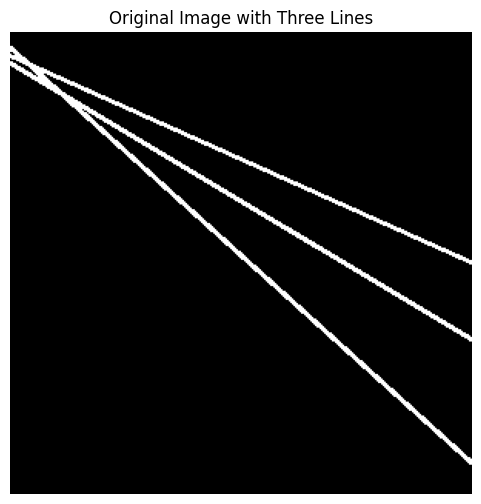

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a black image
img = np.zeros((300, 300), dtype=np.uint8)

# Given slope (m) and intercept (c)
lines = [(90, 10), (45, 15), (60, 20)]

# Draw lines: y = mx + c
# Scale m by 1/100 to fit the image
for m, c in lines:
    x1, x2 = 0, 299
    y1 = int((m / 100) * x1 + c)
    y2 = int((m / 100) * x2 + c)

    cv2.line(img, (x1, y1), (x2, y2), 255, 2)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.title("Original Image with Three Lines")
plt.axis("off")
plt.show()

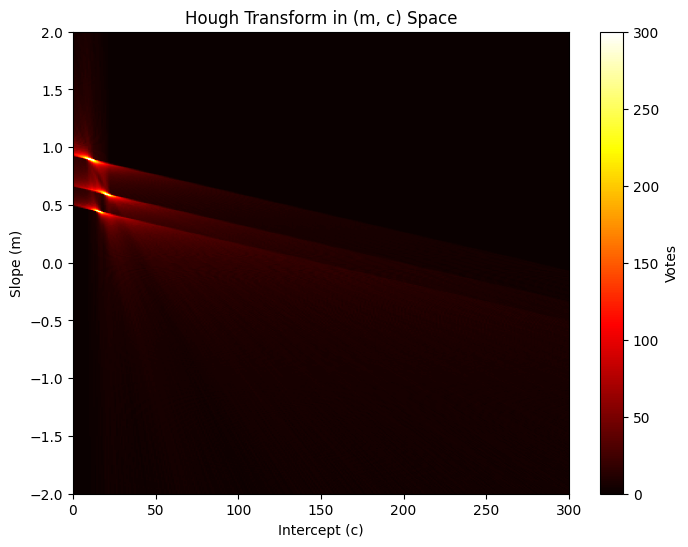

In [2]:
# Get coordinates of white pixels
ys, xs = np.where(img > 0)

# Define slope values
m_values = np.linspace(-2, 2, 400)

# Accumulator for (m, c)
accumulator = np.zeros((len(m_values), 300))

# Vote for possible slope-intercept combinations
for x, y in zip(xs, ys):
    for i, m in enumerate(m_values):
        c = y - m * x

        c_index = int(round(c))

        if 0 <= c_index < 300:
            accumulator[i, c_index] += 1

# Display Hough accumulator
plt.figure(figsize=(8, 6))
plt.imshow(
    accumulator,
    cmap='hot',
    aspect='auto',
    origin='lower',
    extent=[0, 300, m_values[0], m_values[-1]]
)

plt.xlabel("Intercept (c)")
plt.ylabel("Slope (m)")
plt.title("Hough Transform in (m, c) Space")
plt.colorbar(label="Votes")
plt.show()

Detected lines in (r, theta) space:
Line 1: r = 9.00, theta = 132.00 degrees
Line 2: r = 6.00, theta = 132.00 degrees
Line 3: r = 15.00, theta = 121.00 degrees
Line 4: r = 18.00, theta = 121.00 degrees
Line 5: r = 13.00, theta = 114.00 degrees
Line 6: r = 11.00, theta = 131.00 degrees
Line 7: r = 3.00, theta = 133.00 degrees
Line 8: r = 16.00, theta = 114.00 degrees
Line 9: r = 13.00, theta = 122.00 degrees
Line 10: r = 11.00, theta = 115.00 degrees


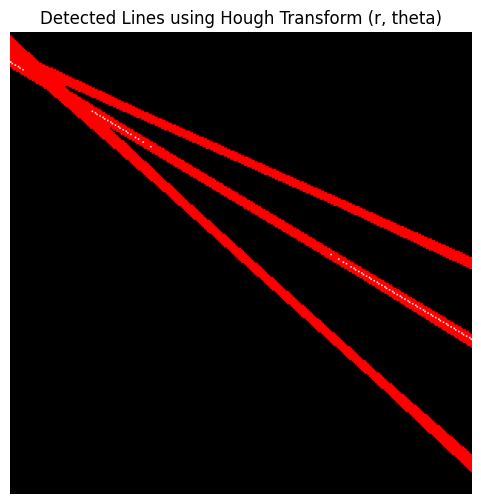

In [ ]:
# Detect edges using Canny
edges = cv2.Canny(img, 50, 150)

# Apply Hough Line Transform
hough_lines = cv2.HoughLines(
    edges,
    1,
    np.pi / 180,
    100
)

# Convert grayscale image to color
result = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

# Draw detected lines
if hough_lines is not None:
    for line in hough_lines:
        rho, theta = line[0]

        a = np.cos(theta)
        b = np.sin(theta)

        x0 = a * rho
        y0 = b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        cv2.line(result, (x1, y1), (x2, y2), (0, 0, 255), 1)

# Display detected lines
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Hough Transform in (r, theta) Space")
plt.axis("off")
plt.show()